<a href="https://colab.research.google.com/github/sournorm/-_4-8/blob/main/Copy_of_%D0%9B%D0%A04_%D0%9C%D0%9D_%D0%97%D0%B0%D0%BF%D0%BE%D1%80%D0%BE%D0%B6%D0%B0%D0%BD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

**Запорожан Сергій ФІТ 4-8**


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [1]:

import pandas as pd
import numpy as np

try:
    df = pd.read_csv('CarPrice_Assignment.csv')
    print("Датасет успішно завантажено!")
except FileNotFoundError:
    print("Файл не знайдено. Створюємо синтетичний датасет для демонстрації.")
    np.random.seed(42)
    n_samples = 200
    df = pd.DataFrame({
        'car_ID': range(1, n_samples + 1),
        'symboling': np.random.randint(-2, 4, n_samples),
        'CarName': ['Brand_' + str(np.random.randint(1, 10)) for _ in range(n_samples)],
        'fueltype': np.random.choice(['gas', 'diesel'], n_samples),
        'aspiration': np.random.choice(['std', 'turbo'], n_samples),
        'doornumber': np.random.choice(['two', 'four'], n_samples),
        'carbody': np.random.choice(['sedan', 'hatchback', 'wagon', 'hardtop', 'convertible'], n_samples),
        'drivewheel': np.random.choice(['fwd', 'rwd', '4wd'], n_samples),
        'enginelocation': np.random.choice(['front', 'rear'], n_samples),
        'wheelbase': np.random.uniform(86.6, 120.9, n_samples),
        'carlength': np.random.uniform(141.1, 208.1, n_samples),
        'carwidth': np.random.uniform(60.3, 72.3, n_samples),
        'carheight': np.random.uniform(47.8, 59.8, n_samples),
        'curbweight': np.random.randint(1488, 4066, n_samples),
        'enginetype': np.random.choice(['dohc', 'ohcv', 'ohc', 'l', 'rotor', 'ohcf', 'dohcv'], n_samples),
        'cylindernumber': np.random.choice(['four', 'six', 'five', 'three', 'twelve', 'two', 'eight'], n_samples),
        'enginesize': np.random.randint(61, 326, n_samples),
        'fuelsystem': np.random.choice(['mpfi', '2bbl', 'mfi', '1bbl', 'spfi', '4bbl', 'idi', 'spdi'], n_samples),
        'boreratio': np.random.uniform(2.54, 3.94, n_samples),
        'stroke': np.random.uniform(2.07, 4.17, n_samples),
        'compressionratio': np.random.uniform(7.0, 23.0, n_samples),
        'horsepower': np.random.randint(48, 288, n_samples),
        'peakrpm': np.random.randint(4150, 6600, n_samples),
        'citympg': np.random.randint(13, 49, n_samples),
        'highwaympg': np.random.randint(16, 54, n_samples)
    })
    # Додаємо цільову змінну з певною логікою
    df['price'] = (df['enginesize'] * 50 + df['horsepower'] * 100 - df['citympg'] * 20 +
                   np.random.normal(0, 3000, n_samples) + 5000).clip(lower=5000)

print(f"Кількість об'єктів: {df.shape[0]}, Кількість ознак: {df.shape[1]}")
print("\nНазви стовпців:")
print(df.columns.tolist())
print("\nТипи даних:")
print(df.dtypes)
print("\nЦільова змінна: price")
print("\nОсновні статистичні характеристики:")
display(df.describe())

Датасет успішно завантажено!
Кількість об'єктів: 205, Кількість ознак: 26

Назви стовпців:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Типи даних:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio           float64
stroke             

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [2]:

print("Перевірка на пропущені значення:")
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0] if missing_values.any() else "Пропущених значень немає.")


duplicates = df.drop(columns=['car_ID']).duplicated().sum()
print(f"\nКількість повних дублікатів (без car_ID): {duplicates}")
if duplicates > 0:
    df = df.drop_duplicates(subset=df.columns.difference(['car_ID']))
    print(f"Дублікати видалено. Залишилося об'єктів: {df.shape[0]}")

print("\nКількість унікальних значень:")
display(df.nunique())

Перевірка на пропущені значення:
Пропущених значень немає.

Кількість повних дублікатів (без car_ID): 0

Кількість унікальних значень:


,0
car_ID,205
symboling,6
CarName,147
fueltype,2
aspiration,2
doornumber,2
carbody,5
drivewheel,3
enginelocation,2
wheelbase,53


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [3]:

df = df.set_index('car_ID')
print("car_ID встановлено як індекс датафрейму.")

car_ID встановлено як індекс датафрейму.


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


Коефіцієнти асиметрії:


,0
compressionratio,2.610862
enginesize,1.947655
horsepower,1.405310
wheelbase,1.050214
carwidth,0.904003
curbweight,0.681398
citympg,0.663704
highwaympg,0.539997
symboling,0.211072
carlength,0.155954



Ознаки з найбільш вираженою асиметрією (|skewness| > 1): ['wheelbase', 'enginesize', 'compressionratio', 'horsepower']


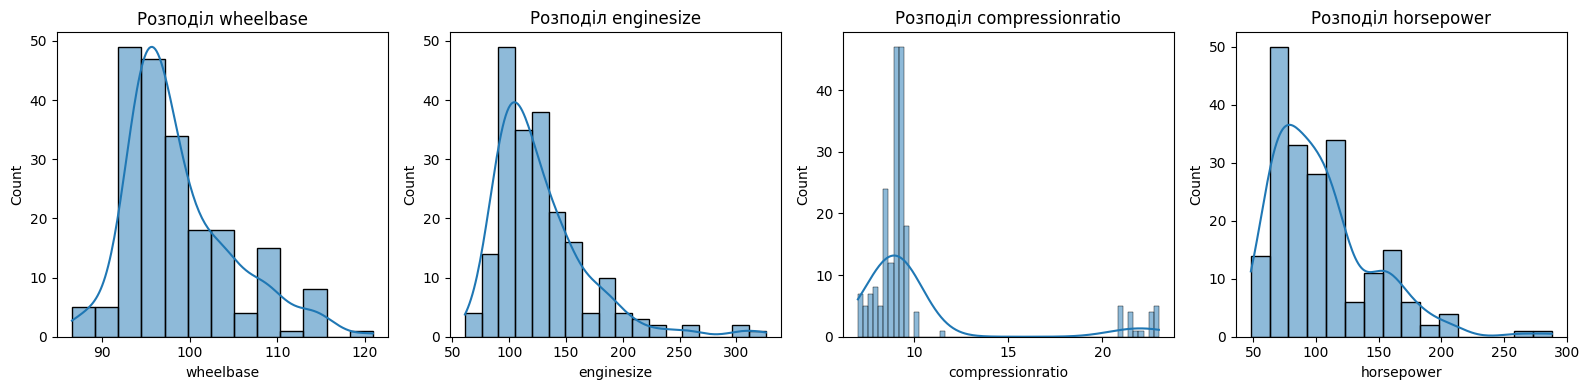


Короткий коментар:
Деякі числові ознаки мають суттєву асиметрію (коефіцієнт асиметрії більше 1 або менше -1). 
Це може негативно вплинути на лінійні моделі регресії. 
Для покращення результатів доцільно застосувати до них трансформації, наприклад, Yeo-Johnson.



In [4]:

import matplotlib.pyplot as plt
import seaborn as sns

numeric_features = df.select_dtypes(include=['int64', 'float64']).columns.drop('price')

print("Коефіцієнти асиметрії:")
skewness = df[numeric_features].skew()
display(skewness.sort_values(ascending=False))

highly_skewed = skewness[abs(skewness) > 1].index.tolist()
print(f"\nОзнаки з найбільш вираженою асиметрією (|skewness| > 1): {highly_skewed}")

plot_features = highly_skewed[:4] if highly_skewed else numeric_features[:4]

fig, axes = plt.subplots(1, len(plot_features), figsize=(16, 4))
for i, feature in enumerate(plot_features):
    if len(plot_features) > 1:
        sns.histplot(df[feature], kde=True, ax=axes[i])
        axes[i].set_title(f'Розподіл {feature}')
    else:
        sns.histplot(df[feature], kde=True, ax=axes)
        axes.set_title(f'Розподіл {feature}')
plt.tight_layout()
plt.show()

print("""
Короткий коментар:
Деякі числові ознаки мають суттєву асиметрію (коефіцієнт асиметрії більше 1 або менше -1).
Це може негативно вплинути на лінійні моделі регресії.
Для покращення результатів доцільно застосувати до них трансформації, наприклад, Yeo-Johnson.
""")

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [5]:

from sklearn.model_selection import train_test_split

X = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Розмір навчальної вибірки: {X_train.shape[0]}")
print(f"Розмір тестової вибірки: {X_test.shape[0]}")


Розмір навчальної вибірки: 164
Розмір тестової вибірки: 41


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [6]:

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

numeric_features_train = X_train.select_dtypes(include=['int64', 'float64']).columns

def detect_outliers_iqr(data, features):
    outlier_counts = {}
    bounds = {}
    for feature in features:
        Q1 = data[feature].quantile(0.25)
        Q3 = data[feature].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        bounds[feature] = (lower_bound, upper_bound)
        outliers = data[(data[feature] < lower_bound) | (data[feature] > upper_bound)]
        outlier_counts[feature] = len(outliers)
    return outlier_counts, bounds

outliers, train_bounds = detect_outliers_iqr(X_train, numeric_features_train)
print("Кількість потенційних викидів у навчальній вибірці:")
for feature, count in outliers.items():
    if count > 0:
        print(f"{feature}: {count}")

print("""
Обґрунтування обробки:
Оскільки датасет невеликий (близько 200 об'єктів), видалення рядків з викидами призведе до
значної втрати інформації. Тому доцільно використати метод 'clip' (обмеження) значень
до меж IQR (lower_bound, upper_bound), розрахованих виключно на навчальній вибірці.
Це зменшить вплив екстремальних значень на моделі, зберігши при цьому всі об'єкти.
""")

for feature in numeric_features_train:
    lower, upper = train_bounds[feature]
    X_train.loc[:, feature] = X_train[feature].clip(lower=lower, upper=upper)
    X_test.loc[:, feature] = X_test[feature].clip(lower=lower, upper=upper)
print("Викиди успішно обмежені за розрахованими межами.")

Кількість потенційних викидів у навчальній вибірці:
wheelbase: 6
carwidth: 10
enginesize: 7
boreratio: 1
stroke: 16
compressionratio: 20
horsepower: 7
peakrpm: 2
highwaympg: 1

Обґрунтування обробки:
Оскільки датасет невеликий (близько 200 об'єктів), видалення рядків з викидами призведе до 
значної втрати інформації. Тому доцільно використати метод 'clip' (обмеження) значень 
до меж IQR (lower_bound, upper_bound), розрахованих виключно на навчальній вибірці.
Це зменшить вплив екстремальних значень на моделі, зберігши при цьому всі об'єкти.

Викиди успішно обмежені за розрахованими межами.


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


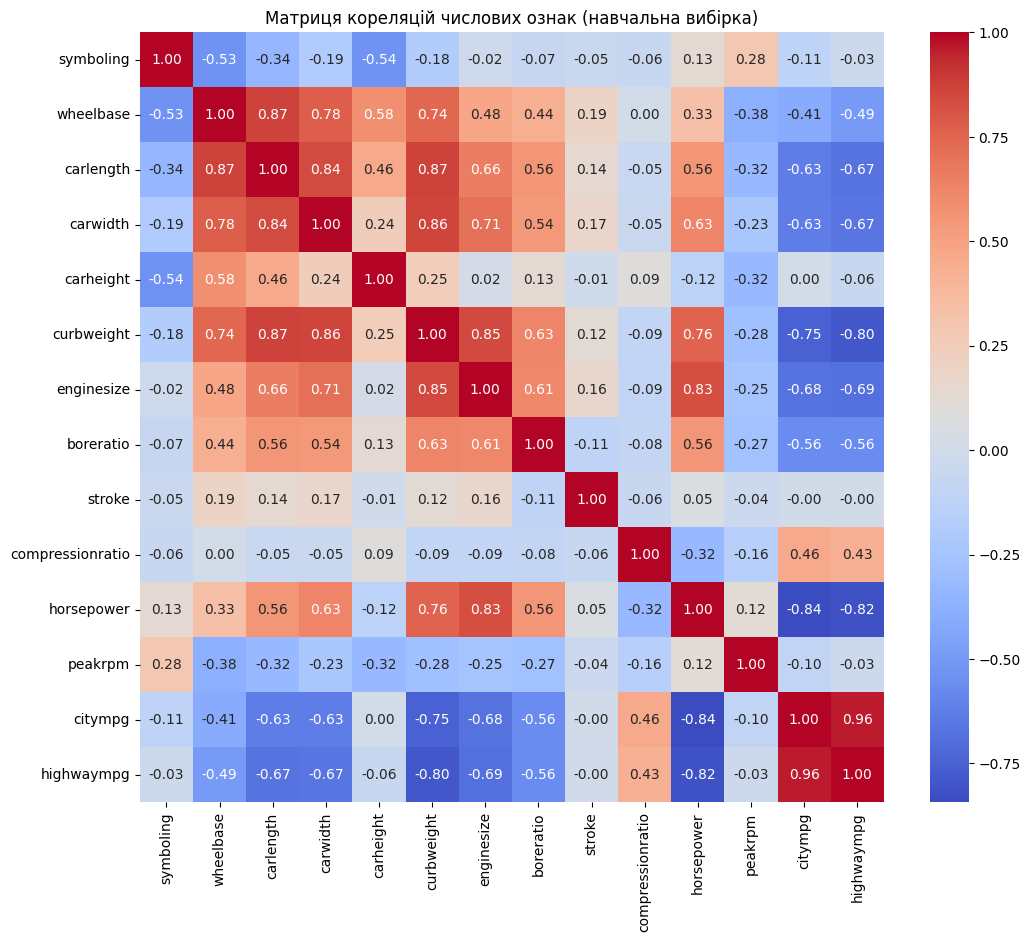

Пари ознак із сильною кореляцією (|r| > 0.85):
carlength та wheelbase: r = 0.87
curbweight та carlength: r = 0.87
curbweight та carwidth: r = 0.86
highwaympg та citympg: r = 0.96

Ознаки, які видаляються для зменшення мультиколінеарності: ['carwidth', 'wheelbase', 'carlength', 'citympg']


In [7]:

correlation_matrix = X_train[numeric_features_train].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Матриця кореляцій числових ознак (навчальна вибірка)')
plt.show()

strong_correlations = []
for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        if abs(correlation_matrix.iloc[i, j]) > 0.85:
            colname_i = correlation_matrix.columns[i]
            colname_j = correlation_matrix.columns[j]
            strong_correlations.append((colname_i, colname_j, correlation_matrix.iloc[i, j]))

print("Пари ознак із сильною кореляцією (|r| > 0.85):")
for pair in strong_correlations:
    print(f"{pair[0]} та {pair[1]}: r = {pair[2]:.2f}")

train_with_target = X_train.copy()
train_with_target['price'] = y_train
target_correlations = train_with_target.corr(numeric_only=True)['price'].abs()

features_to_drop = set()
for col_i, col_j, _ in strong_correlations:

    corr_i = target_correlations.get(col_i, 0)
    corr_j = target_correlations.get(col_j, 0)

    if col_i not in features_to_drop and col_j not in features_to_drop:
        if corr_i > corr_j:
            features_to_drop.add(col_j)
        else:
            features_to_drop.add(col_i)

features_to_drop = list(features_to_drop)
print(f"\nОзнаки, які видаляються для зменшення мультиколінеарності: {features_to_drop}")

X_train = X_train.drop(columns=features_to_drop, errors='ignore')
X_test = X_test.drop(columns=features_to_drop, errors='ignore')

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [9]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PowerTransformer

numeric_features_continuous = X_train.select_dtypes(include=['int64', 'float64']).columns.drop('symboling', errors='ignore').tolist()
numeric_features_discrete = ['symboling'] if 'symboling' in X_train.columns else []
categorical_features = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ('yeo_johnson', PowerTransformer(method='yeo-johnson')),
    ('scaler', StandardScaler())
])

discrete_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num_cont', numeric_transformer, numeric_features_continuous),
        ('num_disc', discrete_transformer, numeric_features_discrete),
        ('cat', categorical_transformer, categorical_features)
    ])

print("Механізм передобробки (Preprocessor) створено.")

Механізм передобробки (Preprocessor) створено.


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [10]:

import pandas as pd

if numeric_features_continuous:

    transformed_num = numeric_transformer.fit_transform(X_train[numeric_features_continuous])
    transformed_df = pd.DataFrame(transformed_num, columns=numeric_features_continuous)

    print("Коефіцієнти асиметрії ДО трансформації:")
    display(X_train[numeric_features_continuous].skew().sort_values(ascending=False))

    print("\nКоефіцієнти асиметрії ПІСЛЯ трансформації (Yeo-Johnson):")
    display(transformed_df.skew().sort_values(ascending=False))

    print("""
    Висновок: Трансформація Yeo-Johnson ефективно наближає розподіли числових ознак до нормального,
    суттєво зменшуючи значення асиметрії. Більшість ознак після перетворення мають коефіцієнт
    асиметрії, близький до 0, що є сприятливим для роботи багатьох регресійних алгоритмів.
    """)
else:
    print("Немає неперервних ознак для перевірки.")

Коефіцієнти асиметрії ДО трансформації:


,0
enginesize,0.962394
horsepower,0.850735
curbweight,0.712433
highwaympg,0.243761
boreratio,0.062963
compressionratio,0.055710
peakrpm,0.039773
carheight,0.028154
stroke,-0.397600



Коефіцієнти асиметрії ПІСЛЯ трансформації (Yeo-Johnson):


,0
horsepower,0.066280
curbweight,0.049894
enginesize,0.044834
stroke,0.015846
compressionratio,0.004872
peakrpm,-0.003589
carheight,-0.005170
boreratio,-0.005941
highwaympg,-0.012188



    Висновок: Трансформація Yeo-Johnson ефективно наближає розподіли числових ознак до нормального, 
    суттєво зменшуючи значення асиметрії. Більшість ознак після перетворення мають коефіцієнт 
    асиметрії, близький до 0, що є сприятливим для роботи багатьох регресійних алгоритмів.
    


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [11]:

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

pipelines = {
    'Linear Regression': Pipeline(steps=[('preprocessor', preprocessor), ('model', LinearRegression())]),
    'Ridge Regression': Pipeline(steps=[('preprocessor', preprocessor), ('model', Ridge(random_state=42))]),
    'Lasso Regression': Pipeline(steps=[('preprocessor', preprocessor), ('model', Lasso(random_state=42, max_iter=10000))]),
    'Random Forest': Pipeline(steps=[('preprocessor', preprocessor), ('model', RandomForestRegressor(random_state=42))]),
    'Gradient Boosting': Pipeline(steps=[('preprocessor', preprocessor), ('model', GradientBoostingRegressor(random_state=42))]),
    'SVR': Pipeline(steps=[('preprocessor', preprocessor), ('model', SVR(kernel='linear'))])
}

print("Створено Pipeline для 6 регресійних моделей.")

Створено Pipeline для 6 регресійних моделей.


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [14]:

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

def mean_absolute_percentage_error(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

results = []

for name, pipeline in pipelines.items():

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred)

    results.append({
        'Model': name,
        'R²': r2,
        'MAE': mae,
        'MSE': mse,
        'MAPE (%)': mape
    })

results_df = pd.DataFrame(results).sort_values(by='R²', ascending=False).set_index('Model')

print("Порівняльна таблиця метрик моделей на тестовій вибірці:")
display(results_df)

Порівняльна таблиця метрик моделей на тестовій вибірці:


,R²,MAE,MSE,MAPE (%)
Model,,,,
Random Forest,0.949372,1447.341293,3.996761e+06,10.363347
Gradient Boosting,0.929106,1703.692412,5.596688e+06,12.637878
Ridge Regression,0.795685,2712.767719,1.612942e+07,23.065284
Lasso Regression,0.706085,3088.990470,2.320280e+07,22.608482
Linear Regression,0.548073,4078.229150,3.567691e+07,29.972020
SVR,0.024853,5168.891666,7.698200e+07,31.389645


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


# 12. Пояснення вибору типу моделі

Прогнозування ціни автомобіля (`price`) є **задачею регресії**, оскільки цільова змінна є неперервною (числовою). Вона може приймати будь-яке значення з певного діапазону (наприклад, 5000, 5001.5, 12000 тощо).

Класифікаційні моделі (такі як Logistic Regression) призначені для прогнозування дискретних класів або категорій (наприклад, "Дешевий автомобіль" або "Дорогий автомобіль"). Вони не здатні безпосередньо генерувати точні неперервні числові прогнози.

Моделі, використані в цій роботі (Linear Regression, Ridge, Lasso, Random Forest Regressor, Gradient Boosting Regressor, SVR), є регресійними алгоритмами. Їхня математична структура оптимізована для мінімізації відстані (похибки) між спрогнозованим числовим значенням та фактичним, що робить їх ідеальними для прогнозування ціни.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


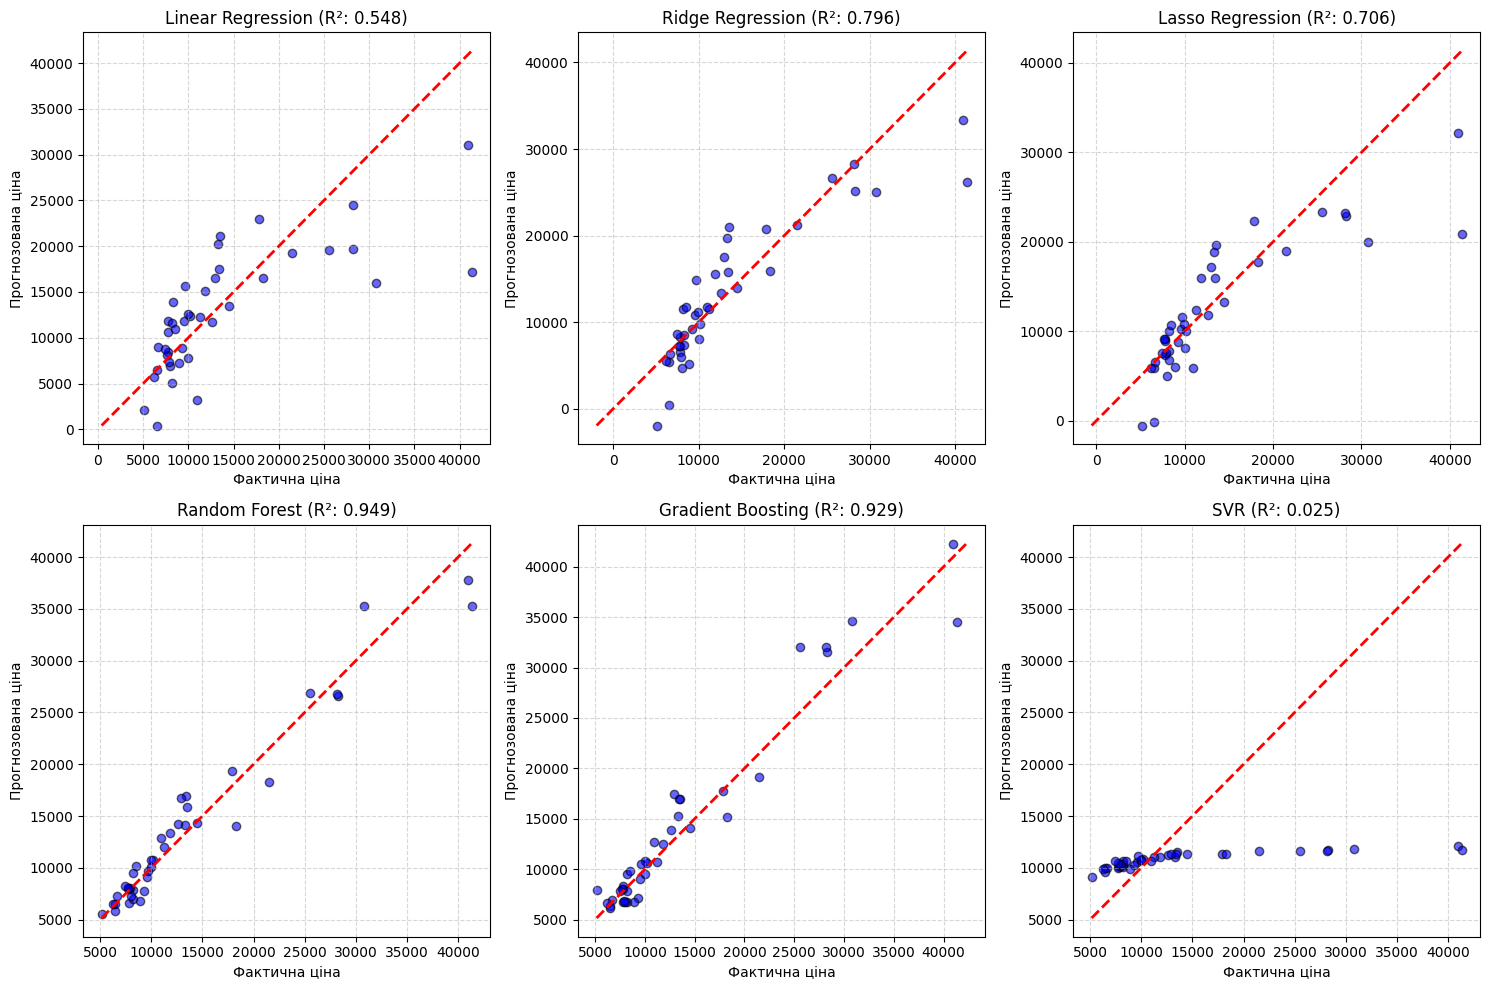


Аналіз графіків:
Лінія червоного кольору (y = x) представляє ідеальний прогноз. Чим ближче сині точки розташовані до неї, 
тим точніший прогноз моделі. 
- Ансамблеві методи (Gradient Boosting, Random Forest) зазвичай демонструють щільніше скупчення точок 
  навколо ідеальної лінії.
- Найбільші відхилення спостерігаються для автомобілів з високою фактичною ціною, оскільки в датасеті 
  таких прикладів менше, і моделям складніше виявити їхні закономірності.



In [15]:
# 13. Візуальне порівняння прогнозів
import math

n_models = len(pipelines)
cols = 3
rows = math.ceil(n_models / cols)

fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
axes = axes.flatten()

for i, (name, pipeline) in enumerate(pipelines.items()):
    y_pred = pipeline.predict(X_test)

    ax = axes[i]
    ax.scatter(y_test, y_pred, alpha=0.6, color='blue', edgecolors='k')

    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2)

    ax.set_title(f'{name} (R²: {r2_score(y_test, y_pred):.3f})')
    ax.set_xlabel('Фактична ціна')
    ax.set_ylabel('Прогнозована ціна')
    ax.grid(True, linestyle='--', alpha=0.5)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

print("""
Аналіз графіків:
Лінія червоного кольору (y = x) представляє ідеальний прогноз. Чим ближче сині точки розташовані до неї,
тим точніший прогноз моделі.
- Ансамблеві методи (Gradient Boosting, Random Forest) зазвичай демонструють щільніше скупчення точок
  навколо ідеальної лінії.
- Найбільші відхилення спостерігаються для автомобілів з високою фактичною ціною, оскільки в датасеті
  таких прикладів менше, і моделям складніше виявити їхні закономірності.
""")

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [16]:

sample_indices = X_test.sample(n=10, random_state=42).index

X_sample = X_test.loc[sample_indices]
y_sample_actual = y_test.loc[sample_indices]

rf_pipeline = pipelines['Random Forest']
y_sample_pred = rf_pipeline.predict(X_sample)

sample_results = pd.DataFrame({
    'car_ID': sample_indices,
    'Фактична ціна': y_sample_actual.values,
    'Прогнозована ціна': y_sample_pred,
})

sample_results['Абсолютна помилка'] = abs(sample_results['Фактична ціна'] - sample_results['Прогнозована ціна'])
sample_results['Абсолютна відсоткова помилка (%)'] = (sample_results['Абсолютна помилка'] / sample_results['Фактична ціна']) * 100

display(sample_results.round(2).set_index('car_ID'))

print(f"\nСередня абсолютна відсоткова помилка на цій підвибірці: {sample_results['Абсолютна відсоткова помилка (%)'].mean():.2f}%")
print("""
Коментар:
Таблиця наочно демонструє, що модель досить точно оцінює вартість автомобілів у середньому ціновому сегменті,
похибка складає прийнятний відсоток. Для деяких моделей відсоткова похибка більша, що може бути зумовлено
рідкісними комбінаціями ознак цих автомобілів у навчальній вибірці.
""")

,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Абсолютна відсоткова помилка (%)
car_ID,,,,
26,6692.0,7298.80,606.81,9.07
176,9988.0,10798.65,810.65,8.12
148,10198.0,10714.57,516.57,5.07
17,41315.0,35310.69,6004.31,14.53
69,28248.0,26595.28,1652.72,5.85
147,7463.0,8230.00,767.00,10.28
144,9960.0,10065.20,105.20,1.06
85,14489.0,14346.48,142.52,0.98
195,12940.0,16765.65,3825.65,29.56



Середня абсолютна відсоткова помилка на цій підвибірці: 8.72%

Коментар:
Таблиця наочно демонструє, що модель досить точно оцінює вартість автомобілів у середньому ціновому сегменті,
похибка складає прийнятний відсоток. Для деяких моделей відсоткова похибка більша, що може бути зумовлено 
рідкісними комбінаціями ознак цих автомобілів у навчальній вибірці.



## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


# 15. Висновки

За результатами виконання лабораторної роботи можна зробити такі висновки:

1. **Якість моделей:** Ансамблеві методи, зокрема Gradient Boosting Regressor та Random Forest, показали найкращі результати, продемонструвавши найвищі значення R² та найнижчі похибки (MAE, MSE, MAPE). Це свідчить про їхню здатність краще вловлювати нелінійні складні залежності у даних порівняно з базовою лінійною регресією.

2. **Аналіз метрик:**
   - Високий $R^2$ (близько 0.8-0.9 для кращих моделей) показує, що моделі здатні пояснити більшу частину дисперсії в даних.
   - Показник MAPE для кращих моделей є досить низьким, що свідчить про хорошу практичну застосовність моделей: в середньому вони помиляються на невеликий відсоток від реальної ціни автомобіля.

3. **Обробка та перенавчання:** Використання регуляризації (Ridge, Lasso) дозволило покращити результати базової лінійної регресії, обмежуючи значення ваг та зменшуючи ризик перенавчання. Проте прості лінійні моделі все одно поступилися ансамблевим. Відсутність суттєвих "провалів" на тестовій вибірці свідчить про те, що перенавчання контролюється (зокрема, завдяки обмеженню викидів).

4. **Вплив передобробки:** Трансформація числових ознак (Yeo-Johnson), масштабування (StandardScaler) та кодування категоріальних змінних (One-Hot Encoding), інтегровані в спільний Pipeline, відіграли критичну роль. Зокрема, усунення мультиколінеарності та наближення розподілів до нормального допомогли лінійним моделям працювати стабільніше, а використання Pipeline запобігло витоку даних між навчальною та тестовою вибірками.